# MRI conductivity from repeated transceive phase

## 1. Problem

We reconstruct a spatial **apparent conductivity** field from 25 real repeated phase volumes. The phase-only Helmholtz approximation assumes the transmit phase is half the measured transceive phase. Spatial differentiation makes the reconstruction sensitive to noise and missing neighbors. This notebook actively reconstructs the bound observations with the local implementation. Frozen original EPTlib results are comparison measurements, never fresh results or independently measured material truth.

The selected scope is the phase-only baseline in the ISMRM 2021 uncertainty study (abstract 3777), with actual stencil, repeatability and magnitude-assisted comparisons. The paper's complete James-Stein spatial covariance estimator is outside this baseline's scope. The nominal saline bulk value has no independent experimental characterization and is not a ground-truth field.

In [1]:
from pathlib import Path
import sys, os, time, json, hashlib, platform
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import correlate
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations, average_repeats
from src.physics_model import (phase_conductivity, full_helmholtz, second_derivative_kernels,
    kernel_geometry, valid_support, MU0, OMEGA, FREQUENCY_HZ, SPACING_XYZ)
from src.solvers import reconstruct, reconstruct_repeats
from src.visualization import agreement, slice_image
FIG=Path(os.environ['IMAGING_REVIEW_FIGURE_DIR']);FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'figure.dpi':110,'savefig.dpi':160,
                     'svg.fonttype':'none','pdf.fonttype':42})
started=time.perf_counter();figure_sources=[]
def export(fig,name,arrays,description):
    fig.savefig(FIG/(name+'.png'),bbox_inches='tight')
    fig.savefig(FIG/(name+'.svg'),bbox_inches='tight')
    fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight')
    np.savez_compressed(FIG/(name+'.npz'),**arrays)
    row={'figure':name,'description':description,'numeric_keys':list(arrays),
         'files':{ext:{'file':name+'.'+ext,'sha256':hashlib.sha256((FIG/(name+'.'+ext)).read_bytes()).hexdigest()} for ext in ['png','svg','pdf','npz']}}
    (FIG/(name+'.json')).write_text(json.dumps(row,indent=2),encoding='utf-8')
    figure_sources.append(row);plt.show();plt.close(fig)
def zoom(ax,half=32): ax.set_xlim(-half,half);ax.set_ylim(-half,half)
environment={'python':sys.version,'executable':sys.executable,'platform':platform.platform(),
             'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,
             'OMP_NUM_THREADS':os.environ.get('OMP_NUM_THREADS')}
print(json.dumps(environment,indent=2))

{
  "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "platform": "Windows-10-10.0.26200-SP0",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "OMP_NUM_THREADS": "1"
}


## 2. Data

The native arrays retain every acquisition voxel and all 25 scans, in repeat,z,y,x order after removing the batch axis. Spacing is 2 mm along all three axes; frequency is 128 MHz. The authors supplied only a central sphere of radius 30 mm, leaving NaNs outside it. The 11-cuboid derivative needs every neighbor and therefore leaves 859 valid centers. Both masks depend only on input availability. Display zooms below expose this small measured region; no evaluation crop is performed. Magnitude is the supplied transmit-sensitivity approximation in arbitrary common scale, not an independently calibrated absolute magnetic field.

Measured voxels: 11513 primary output: 859 fresh/original: {'ncc': 1.0, 'nrmse': 8.706591655729695e-15}


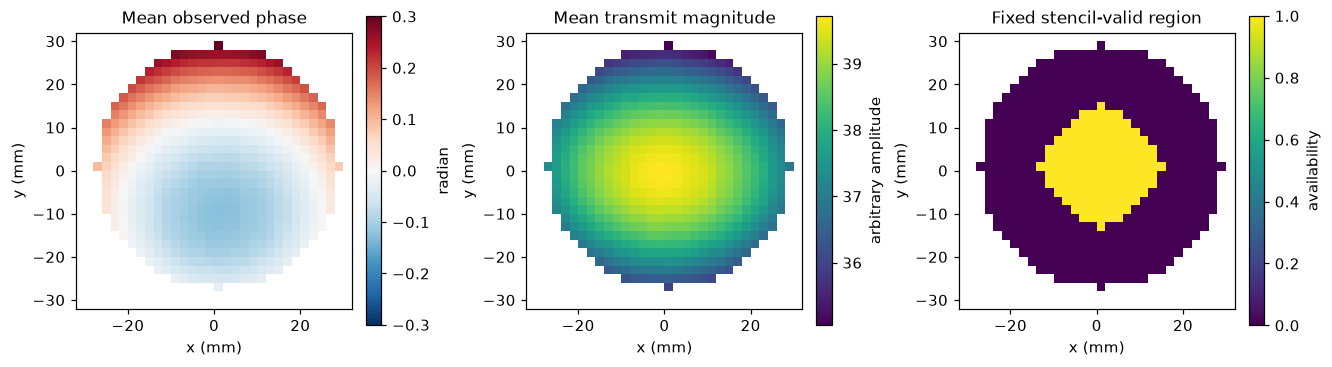

In [2]:
phases,magnitudes,observed=load_observations(ROOT/'data/raw_data.npz')
sigma,support,mean_phase=reconstruct(phases)
mean_magnitude=average_repeats(magnitudes)
with np.load(ROOT/'notebooks/reference_outputs/upstream_results.npz',allow_pickle=False) as a:
    upstream={k:a[k] for k in a.files}
original=upstream['original_s2_r5_phase']
parity=agreement(sigma,original,support)
print('Measured voxels:',observed.sum(),'primary output:',support.sum(),'fresh/original:',parity)
fig,ax=plt.subplots(1,3,figsize=(12,3.6),layout='constrained')
v=float(np.max(abs(mean_phase[observed])))
slice_image(ax[0],mean_phase,observed,'Mean observed phase',unit='radian',cmap='RdBu_r',limits=(-v,v));zoom(ax[0])
slice_image(ax[1],mean_magnitude,observed,'Mean transmit magnitude',unit='arbitrary amplitude');zoom(ax[1])
slice_image(ax[2],support.astype(float),observed,'Fixed stencil-valid region',limits=(0,1),unit='availability');zoom(ax[2])
export(fig,'01_observations',{'mean_phase':mean_phase,'mean_magnitude':mean_magnitude,'observation_mask':observed,'support':support},'Native real input means and input-only geometric support; central axial slice.')

## 3. Physics

With transceive phase $\phi$ in radians, conductivity $\sigma$ in S/m, permeability $\mu_0=4\pi10^{-7}$ H/m and angular frequency $\omega=2\pi f$, the selected approximation is

$$\sigma(\mathbf r)=\frac{\nabla^2\phi(\mathbf r)}{2\mu_0\omega}.$$

The factor two is physical, not a fitted gain. A second derivative with voxel-index coordinates must be divided by the square of physical spacing. A spatially constant phase offset cancels. The magnitude-assisted comparison instead constructs $U=A\exp(i\phi/2)$ and uses

$$\epsilon_c=-\frac{\nabla^2 U}{\mu_0\omega^2 U},\qquad
\sigma=-\omega\operatorname{Im}\epsilon_c,\qquad \epsilon_r=\operatorname{Re}\epsilon_c/\epsilon_0.$$

Here $A$ is supplied magnitude and $\epsilon_0=1/(\mu_0 c_0^2)$ with $c_0=299792458$ m/s. Neither comparison is independent experimental truth. We test physical factors using analytic fields, separately from the real observations.

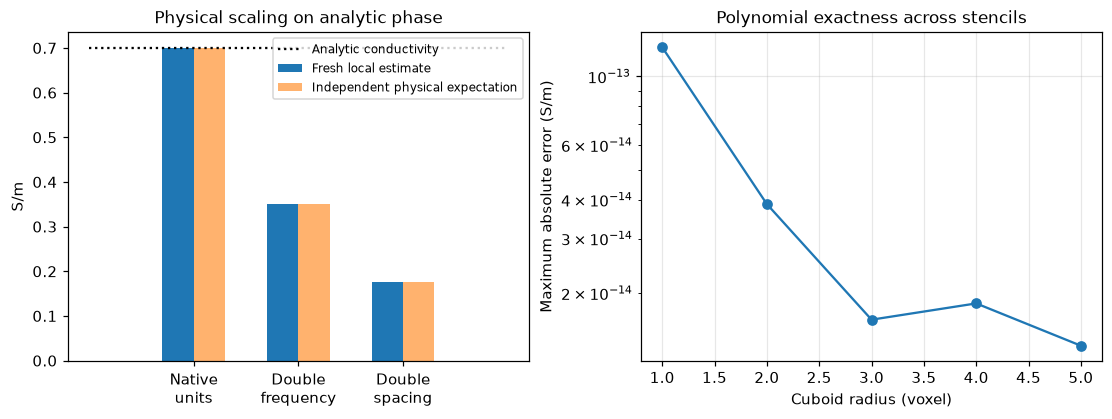

In [3]:
n=41;h=.002;z,y,x=np.indices((n,n,n),dtype=float);x=(x-20)*h;y=(y-20)*h;z=(z-20)*h
known_sigma=.7
analytic_phase=MU0*OMEGA*known_sigma*(x*x+y*y+z*z)/3
analytic_est,amask=phase_conductivity(analytic_phase)
frequency_est,_=phase_conductivity(analytic_phase,frequency=2*FREQUENCY_HZ)
spacing_est,_=phase_conductivity(analytic_phase,spacing=(2*h,2*h,2*h))
physics_values=np.array([np.mean(analytic_est[amask]),np.mean(frequency_est[amask]),np.mean(spacing_est[amask])])
physics_expected=known_sigma*np.array([1,.5,.25])
offset_est,_=phase_conductivity(analytic_phase+1.25)
assert np.max(abs(analytic_est[amask]-known_sigma))<1e-10
assert np.max(abs(offset_est[amask]-analytic_est[amask]))<1e-9
fig,ax=plt.subplots(1,2,figsize=(10,3.7),layout='constrained')
ax[0].plot([-1,3],[known_sigma]*2,'k:',label='Analytic conductivity')
ax[0].bar(np.arange(3)-.15,physics_values,.3,label='Fresh local estimate')
ax[0].bar(np.arange(3)+.15,physics_expected,.3,label='Independent physical expectation',alpha=.6)
ax[0].set(xticks=range(3),xticklabels=['Native\nunits','Double\nfrequency','Double\nspacing'],ylabel='S/m',title='Physical scaling on analytic phase');ax[0].legend(fontsize=8)
errors=[]
for radius in range(1,6):
    estimate,msk=phase_conductivity(analytic_phase,'cube',radius)
    errors.append(np.max(abs(estimate[msk]-known_sigma)))
ax[1].semilogy(range(1,6),errors,'o-');ax[1].set(xlabel='Cuboid radius (voxel)',ylabel='Maximum absolute error (S/m)',title='Polynomial exactness across stencils');ax[1].grid(alpha=.3)
export(fig,'02_independent_physics',{'analytic_phase':analytic_phase,'fresh_sigma':analytic_est,'support':amask,'measured_scaling':physics_values,'expected_scaling':physics_expected,'polynomial_errors':np.array(errors)},'Independent analytic phase, frequency and physical spacing checks; no new measured observations.')

## 4. Method

Repeat averaging sums each float64-cast observation divided by 25, preserving the source's order. At each available center a quadratic polynomial is fit over an 11-by-11-by-11 cuboid. Symmetry decouples the even basis $F=[1,x^2,y^2,z^2]$ from odd terms. Twice the appropriate row of $(F^T F)^{-1}F^T$ gives each second-derivative stencil; coordinates here are integer voxel offsets. Physical spacing is applied afterward. This closed-form estimate has no iteration, regularizer or convergence threshold. Missing neighbors invalidate a center rather than inventing extrapolated data.

We compare every original stencil family (cross, sphere and cube) at radii 1–5. The primary conditional estimator remains the published cuboid-radius-5 case. Frozen original fields establish implementation parity; common-support statistics compare actual fresh estimates on the same 859 centers.

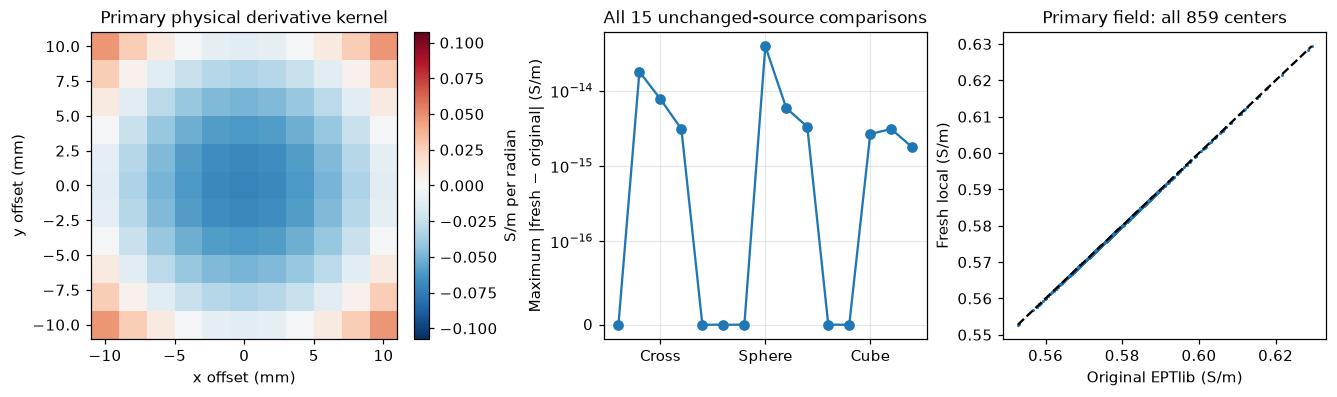

In [4]:
cases=[(name,r) for name in ['cross','sphere','cube'] for r in range(1,6)]
fresh_fields=[];fresh_full=[];fresh_epsr=[];counts=[];stage_errors=[]
for i,(name,radius) in enumerate(cases):
    field,mask=phase_conductivity(mean_phase,name,radius)
    full,epsr,fullmask=full_helmholtz(mean_phase,mean_magnitude,name,radius)
    fresh_fields.append(field);fresh_full.append(full);fresh_epsr.append(epsr);counts.append(mask.sum())
    source=upstream[f'original_s{i//5}_r{radius}_phase']
    assert np.array_equal(mask,np.isfinite(source))
    stage_errors.append(float(np.max(abs(field[mask]-source[mask]))))
fresh_fields=np.stack(fresh_fields);fresh_full=np.stack(fresh_full);fresh_epsr=np.stack(fresh_epsr)
primary_kernel=second_derivative_kernels().sum(axis=0)/h/h/(2*MU0*OMEGA)
fig,ax=plt.subplots(1,3,figsize=(12,3.5),layout='constrained')
maxk=abs(primary_kernel).max()
im=ax[0].imshow(primary_kernel[5],cmap='RdBu_r',vmin=-maxk,vmax=maxk,origin='lower',extent=(-11,11,-11,11),rasterized=True)
plt.colorbar(im,ax=ax[0],label='S/m per radian');ax[0].set(title='Primary physical derivative kernel',xlabel='x offset (mm)',ylabel='y offset (mm)')
ax[1].plot(range(15),stage_errors,'o-');ax[1].set_yscale('symlog',linthresh=1e-16);ax[1].set(xticks=[2,7,12],xticklabels=['Cross','Sphere','Cube'],ylabel='Maximum |fresh − original| (S/m)',title='All 15 unchanged-source comparisons');ax[1].grid(alpha=.3)
ax[2].plot(original[support],sigma[support],'.',ms=2);lim=[original[support].min(),original[support].max()];ax[2].plot(lim,lim,'k--');ax[2].set(xlabel='Original EPTlib (S/m)',ylabel='Fresh local (S/m)',title='Primary field: all 859 centers')
export(fig,'03_method_and_parity',{'kernel_Sm_per_rad':primary_kernel,'stage_max_absolute_error':np.array(stage_errors),'original_primary':original,'fresh_primary':sigma,'support':support},'Locally constructed SG kernel; all fifteen independent original-field comparisons and primary scatter.')

## 5. Results

All maps below are freshly calculated from the real observations. The apparent conductivity field is spatially nonconstant despite the homogeneous preparation: measurement noise and approximation error remain. There is no spatially resolved truth. The extremely strict source-agreement metrics demonstrate numerical extraction, not conductivity accuracy. All scores use the fixed input-derived support without alignment or rescaling.

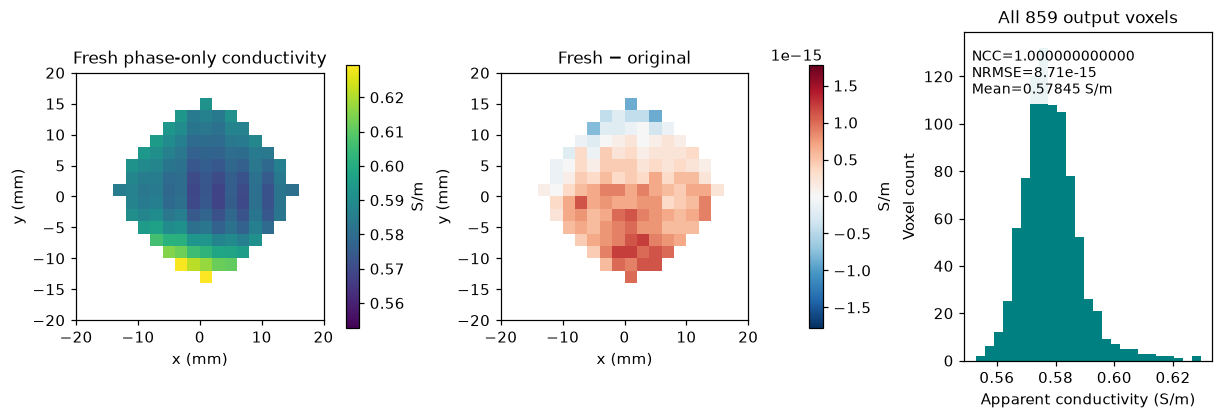

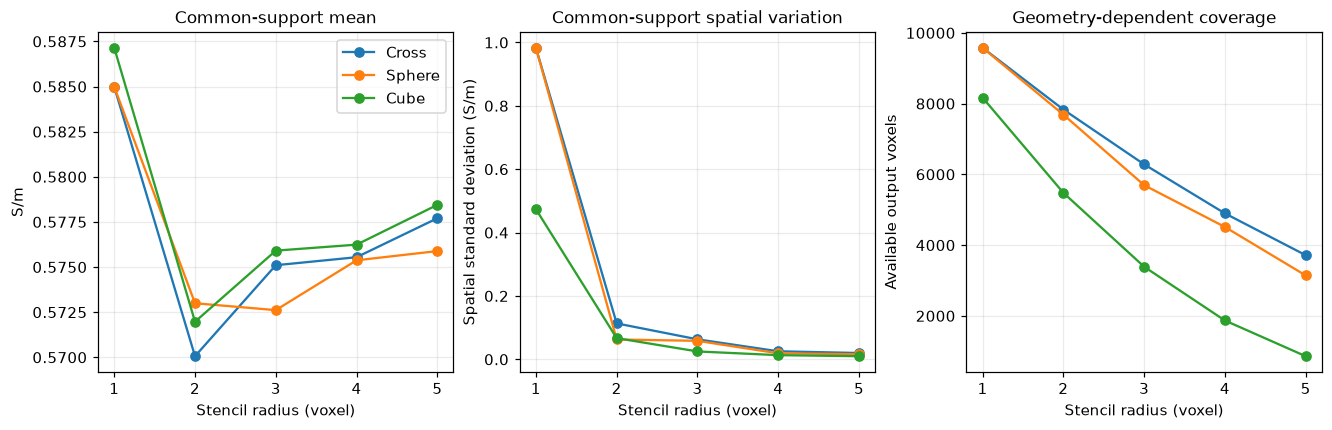

In [5]:
fig,ax=plt.subplots(1,3,figsize=(11,3.7),layout='constrained')
lo,hi=float(sigma[support].min()),float(sigma[support].max())
slice_image(ax[0],sigma,support,'Fresh phase-only conductivity',limits=(lo,hi));zoom(ax[0],20)
difference=sigma-original;maxdiff=np.max(abs(difference[support]))
slice_image(ax[1],difference,support,'Fresh − original',cmap='RdBu_r',limits=(-maxdiff,maxdiff));zoom(ax[1],20)
ax[2].hist(sigma[support],bins=25,color='teal');ax[2].set(xlabel='Apparent conductivity (S/m)',ylabel='Voxel count',title=f'All {support.sum()} output voxels')
ax[2].text(.03,.95,f'NCC={parity["ncc"]:.12f}\nNRMSE={parity["nrmse"]:.3g}\nMean={sigma[support].mean():.5f} S/m',transform=ax[2].transAxes,va='top',fontsize=9,bbox={'facecolor':'white','alpha':.92,'edgecolor':'none'})
export(fig,'04_primary_result',{'fresh':sigma,'original':original,'difference':difference,'support':support},'Primary fresh conductivity and source agreement; no nominal bulk truth overlay.')

means=np.array([a[support].mean() for a in fresh_fields]).reshape(3,5)
spatial_std=np.array([a[support].std() for a in fresh_fields]).reshape(3,5)
fig,ax=plt.subplots(1,3,figsize=(12,3.8),layout='constrained')
for i,name in enumerate(['Cross','Sphere','Cube']):
    ax[0].plot(range(1,6),means[i],'o-',label=name)
    ax[1].plot(range(1,6),spatial_std[i],'o-',label=name)
    ax[2].plot(range(1,6),np.array(counts).reshape(3,5)[i],'o-',label=name)
for a in ax:a.set_xlabel('Stencil radius (voxel)');a.grid(alpha=.25)
ax[0].set(title='Common-support mean',ylabel='S/m');ax[0].legend()
ax[1].set(title='Common-support spatial variation',ylabel='Spatial standard deviation (S/m)')
ax[2].set(title='Geometry-dependent coverage',ylabel='Available output voxels')
export(fig,'05_stencil_sensitivity',{'fresh_fields':fresh_fields,'common_support':support,'means':means,'spatial_std':spatial_std,'valid_counts':np.array(counts)},'Fresh shape/radius sensitivity; common fixed centers for mean/std and separately reported total valid coverage.')

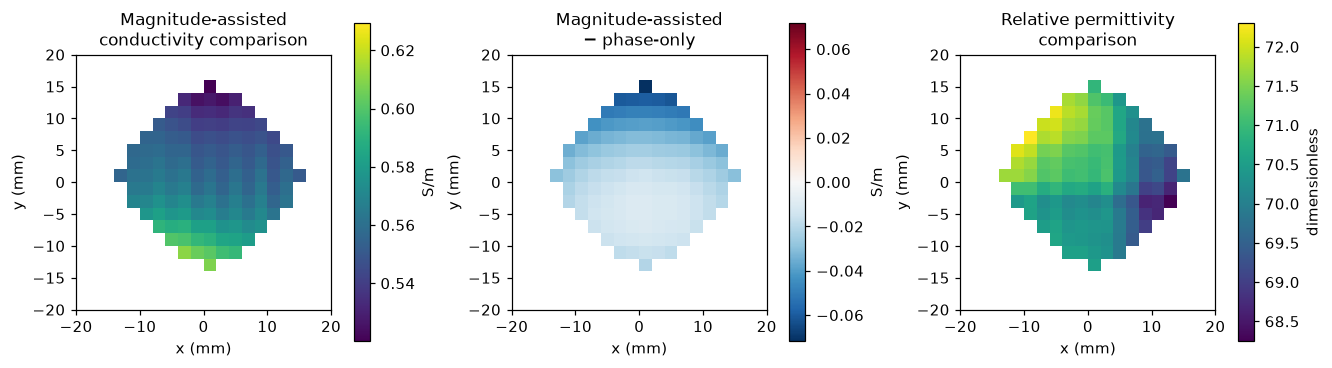

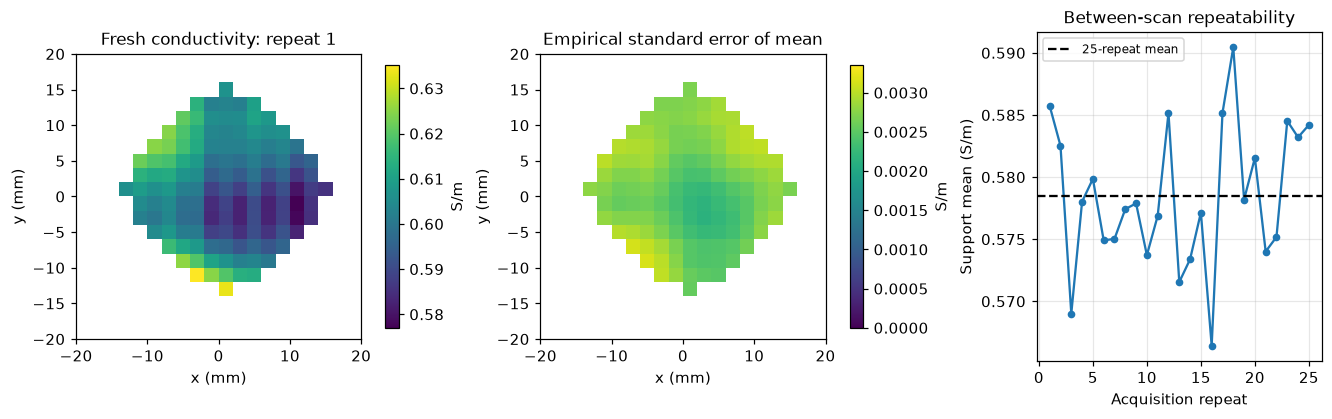

In [6]:
full=fresh_full[-1];epsr=fresh_epsr[-1];contrast=full-sigma
fig,ax=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
joint=(min(sigma[support].min(),full[support].min()),max(sigma[support].max(),full[support].max()))
slice_image(ax[0],full,support,'Magnitude-assisted\nconductivity comparison',limits=joint);zoom(ax[0],20)
v=np.max(abs(contrast[support]));slice_image(ax[1],contrast,support,'Magnitude-assisted\n− phase-only',cmap='RdBu_r',limits=(-v,v));zoom(ax[1],20)
slice_image(ax[2],epsr,support,'Relative permittivity\ncomparison',unit='dimensionless');zoom(ax[2],20)
export(fig,'06_magnitude_assumption',{'phase_sigma':sigma,'full_sigma':full,'relative_permittivity':epsr,'difference':contrast,'support':support},'Fresh original magnitude-assisted equations; systematic differences test a model assumption and are not accuracy errors.')

repeat_sigma=reconstruct_repeats(phases)
repeat_std=np.full(sigma.shape,np.nan);repeat_std[support]=np.std(repeat_sigma[:,support],axis=0,ddof=1)
sem=repeat_std/np.sqrt(len(phases))
repeat_means=repeat_sigma[:,support].mean(axis=1)
fig,ax=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
slice_image(ax[0],repeat_sigma[0],support,'Fresh conductivity: repeat 1');zoom(ax[0],20)
slice_image(ax[1],sem,support,'Empirical standard error of mean',limits=(0,float(sem[support].max())));zoom(ax[1],20)
ax[2].plot(range(1,26),repeat_means,'o-',ms=4);ax[2].axhline(sigma[support].mean(),color='k',ls='--',label='25-repeat mean')
ax[2].set(xlabel='Acquisition repeat',ylabel='Support mean (S/m)',title='Between-scan repeatability');ax[2].legend(fontsize=8);ax[2].grid(alpha=.3)
export(fig,'07_repeatability',{'all_fresh_repeat_sigma':repeat_sigma,'repeat_std_ddof1':repeat_std,'sem':sem,'repeat_means':repeat_means,'support':support},'All 25 fresh repeat reconstructions and empirical sample standard deviation/SEM, not calibrated confidence coverage.')

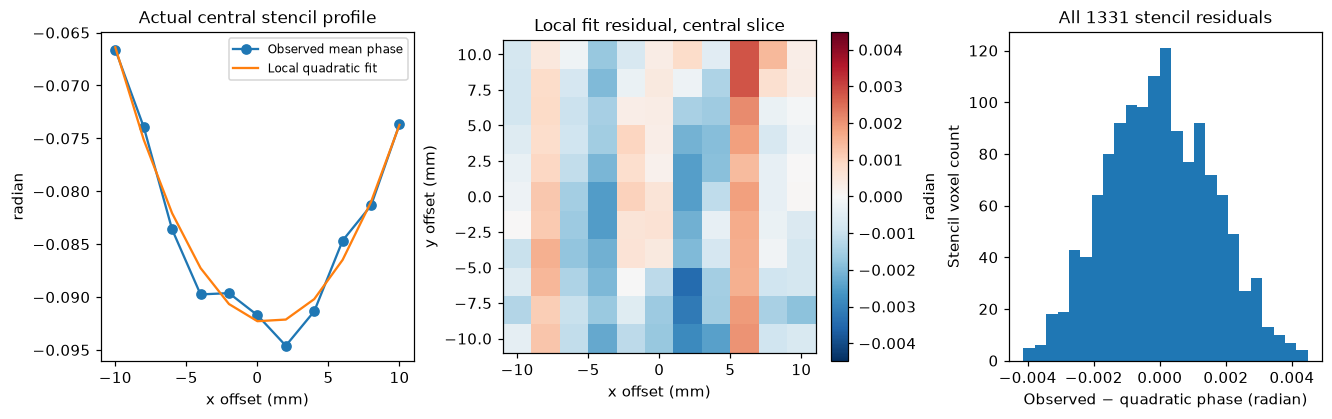

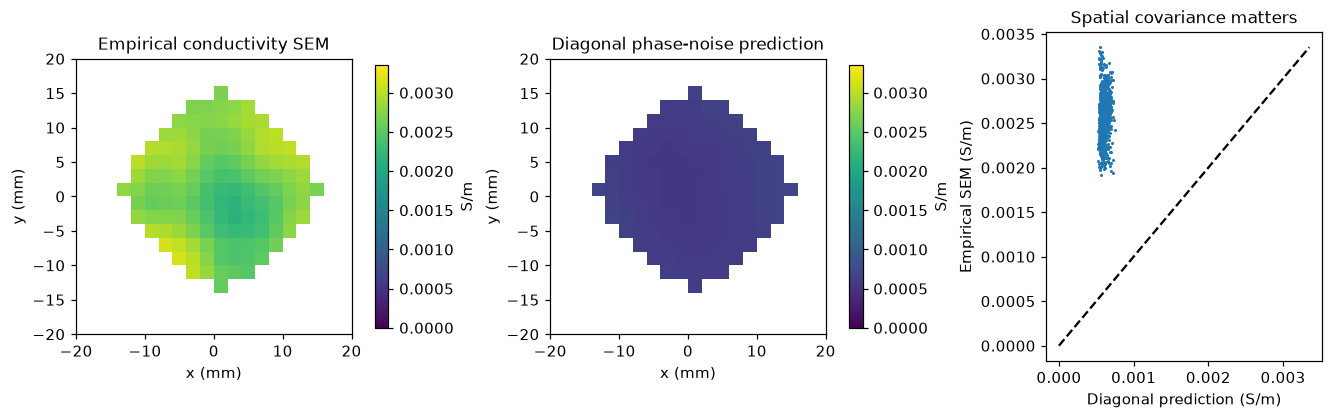

In [7]:
center=tuple(np.round(np.argwhere(support).mean(axis=0)).astype(int))
zz,yy,xx=np.indices((11,11,11),dtype=float)-5
design=np.column_stack([np.ones(xx.size),xx.ravel(),yy.ravel(),zz.ravel(),xx.ravel()**2,yy.ravel()**2,zz.ravel()**2,(xx*yy).ravel(),(xx*zz).ravel(),(yy*zz).ravel()])
region=tuple(slice(i-5,i+6) for i in center)
patch=mean_phase[region];coeff=np.linalg.lstsq(design,patch.ravel(),rcond=None)[0];fitted=(design@coeff).reshape(11,11,11);residual=patch-fitted
fig,ax=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
ax[0].plot(np.arange(-5,6)*2,patch[5,5],'o-',label='Observed mean phase');ax[0].plot(np.arange(-5,6)*2,fitted[5,5],'-',label='Local quadratic fit');ax[0].set(xlabel='x offset (mm)',ylabel='radian',title='Actual central stencil profile');ax[0].legend(fontsize=8)
v=abs(residual).max();im=ax[1].imshow(residual[5],origin='lower',extent=(-11,11,-11,11),cmap='RdBu_r',vmin=-v,vmax=v,rasterized=True);plt.colorbar(im,ax=ax[1],label='radian');ax[1].set(title='Local fit residual, central slice',xlabel='x offset (mm)',ylabel='y offset (mm)')
ax[2].hist(residual.ravel(),bins=25);ax[2].set(xlabel='Observed − quadratic phase (radian)',ylabel='Stencil voxel count',title='All 1331 stencil residuals')
export(fig,'08_actual_fit_residual',{'patch':patch,'quadratic_fitted':fitted,'residual':residual,'quadratic_coefficients':coeff,'center_zyx':np.array(center)},'Full ordinary quadratic fit on an input-selected central stencil; actual observed residuals, not a manufactured forward fit.')

phase_var=np.zeros(sigma.shape);phase_var[observed]=np.var(phases[:,observed].astype(float),axis=0,ddof=1)/25
diagonal_sem=np.sqrt(correlate(phase_var,primary_kernel**2,mode='constant',cval=0))
fig,ax=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
limits=(0,max(float(sem[support].max()),float(diagonal_sem[support].max())))
slice_image(ax[0],sem,support,'Empirical conductivity SEM',limits=limits);zoom(ax[0],20)
slice_image(ax[1],diagonal_sem,support,'Diagonal phase-noise prediction',limits=limits);zoom(ax[1],20)
ax[2].plot(diagonal_sem[support],sem[support],'.',ms=2);v=limits[1];ax[2].plot([0,v],[0,v],'k--');ax[2].set(xlabel='Diagonal prediction (S/m)',ylabel='Empirical SEM (S/m)',title='Spatial covariance matters')
export(fig,'09_noise_propagation',{'phase_variance_of_mean':phase_var,'diagonal_sem':diagonal_sem,'empirical_sem':sem,'support':support},'Fresh empirical phase variance propagated with squared physical stencil; independence approximation compared with actual repeat conductivity variability.')

## 6. Conclusion

The fresh local implementation reproduces the unchanged original method on the same observations while independent analytic tests establish the phase factor, derivative units and frequency convention. Stencil coverage and noise sensitivity are visible rather than hidden by a fitted-value mask. Magnitude-assisted results expose the phase-only approximation, and repeat reconstructions reveal acquisition variability and the limitations of a diagonal noise model.

These results validate numerical reproduction of a conditional phase-only estimate. They do not validate a heterogeneous material truth, replace the paper's complete correlated uncertainty treatment, or establish clinical accuracy. The data were measured on a stationary saline phantom, and the authors supplied only the central spherical region.

In [8]:
from importlib.util import spec_from_file_location,module_from_spec
spec=spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py');judge=module_from_spec(spec);spec.loader.exec_module(judge)
output=ROOT/'output/reconstruction.npz';output.parent.mkdir(exist_ok=True)
np.savez_compressed(output,reconstruction=sigma[None])
report=judge.evaluate(output);assert report['passed'],report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf-8')
summary={'environment':environment,'seconds':time.perf_counter()-started,'original_agreement':parity,
         'maximum_stage_absolute_error':max(stage_errors),'support_voxels':int(support.sum()),
         'phase_sigma_mean_Sm':float(sigma[support].mean()),'phase_sigma_spatial_std_Sm':float(sigma[support].std()),
         'magnitude_assisted_sigma_mean_Sm':float(full[support].mean()),
         'empirical_sem_mean_Sm':float(sem[support].mean()),'diagonal_sem_mean_Sm':float(diagonal_sem[support].mean()),
         'judge':report,'figure_sources':figure_sources}
(FIG/'measurements.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf-8')
print(json.dumps({k:v for k,v in summary.items() if k not in ['figure_sources','environment']},indent=2))

{
  "seconds": 119.43437019998964,
  "original_agreement": {
    "ncc": 1.0,
    "nrmse": 8.706591655729695e-15
  },
  "maximum_stage_absolute_error": 3.9190872769268026e-14,
  "support_voxels": 859,
  "phase_sigma_mean_Sm": 0.5784451209428569,
  "phase_sigma_spatial_std_Sm": 0.009844949261851197,
  "magnitude_assisted_sigma_mean_Sm": 0.5568056271944503,
  "empirical_sem_mean_Sm": 0.002540174600294528,
  "diagonal_sem_mean_Sm": 0.0006003144698103431,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "ncc": 1.0,
      "nrmse": 8.706591655729695e-15
    },
    "thresholds": {
      "ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "nrmse": {
        "comparison": "<=",
        "boundary": 1e-06
      }
    },
    "errors": []
  }
}
